# E3 – Clasificación: Riesgo de impago hipotecario
Modelo base vs. optimizado (`DecisionTreeClassifier`), `random_state = 29`.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, recall_score,
                             precision_score, f1_score, fbeta_score, make_scorer)
RS = 29
TARGET = 'Riesgo_Impago'
COSTO_FN = 1_500_000   # crédito otorgado que termina en impago
COSTO_FP = 200_000     # cliente bueno rechazado (interés no ganado)
sns.set_theme(style='whitegrid')

## Fase 1 – Diagnóstico y calidad de datos (EDA)

In [2]:
df = pd.read_csv('riesgo_crediticio.csv', index_col=0)  # la 1ª columna es un índice exportado
print(df.shape); df.info()
display(df.describe().T)

(25000, 5)
<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Ingreso_Anual           25000 non-null  float64
 1   Monto_Prestamo          25000 non-null  float64
 2   Puntaje_Credito         25000 non-null  float64
 3   Relacion_Deuda_Ingreso  25000 non-null  float64
 4   Riesgo_Impago           25000 non-null  int64  
dtypes: float64(4), int64(1)
memory usage: 976.7 KB


,count,mean,std,min,25%,50%,75%,max
Ingreso_Anual,25000.0,55824.444883,29804.903177,7832.12,35051.3175,49234.685,68923.5200,348135.55
Monto_Prestamo,25000.0,220162.891849,60059.302633,50000.00,179438.0775,220241.470,261003.3625,451784.21
Puntaje_Credito,25000.0,680.033440,59.784266,457.00,640.0000,680.000,721.0000,850.00
Relacion_Deuda_Ingreso,25000.0,24.027319,13.615029,5.00,13.7875,21.450,31.3825,70.00
Riesgo_Impago,25000.0,0.071560,0.257763,0.00,0.0000,0.000,0.0000,1.00


In [3]:
print('Nulos por columna:\n', df.isna().sum())
print('Duplicados:', df.duplicated().sum())
# Inconsistencias lógicas
print('Ingreso <= 0 :', (df.Ingreso_Anual <= 0).sum())
print('Monto <= 0   :', (df.Monto_Prestamo <= 0).sum())
print('Puntaje fuera de [300, 850]:', (~df.Puntaje_Credito.between(300, 850)).sum())
print('DTI < 0 o > 100:', ((df.Relacion_Deuda_Ingreso < 0) | (df.Relacion_Deuda_Ingreso > 100)).sum())
print('DTI == 70 (posible tope/censura):', (df.Relacion_Deuda_Ingreso == 70).sum())
print('Puntaje == 850 (tope):', (df.Puntaje_Credito == 850).sum())
# Outliers (regla IQR)
for c in df.columns.drop(TARGET):
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    print(f'{c}: {n} outliers ({n/len(df):.1%})')

Nulos por columna:
 Ingreso_Anual             0
Monto_Prestamo            0
Puntaje_Credito           0
Relacion_Deuda_Ingreso    0
Riesgo_Impago             0
dtype: int64
Duplicados: 0
Ingreso <= 0 : 0
Monto <= 0   : 0
Puntaje fuera de [300, 850]: 0
DTI < 0 o > 100: 0
DTI == 70 (posible tope/censura): 196
Puntaje == 850 (tope): 49
Ingreso_Anual: 976 outliers (3.9%)
Monto_Prestamo: 157 outliers (0.6%)
Puntaje_Credito: 167 outliers (0.7%)
Relacion_Deuda_Ingreso: 663 outliers (2.7%)


Riesgo_Impago
0    23211
1     1789
Name: count, dtype: int64 
 Riesgo_Impago
0    0.9284
1    0.0716
Name: proportion, dtype: float64


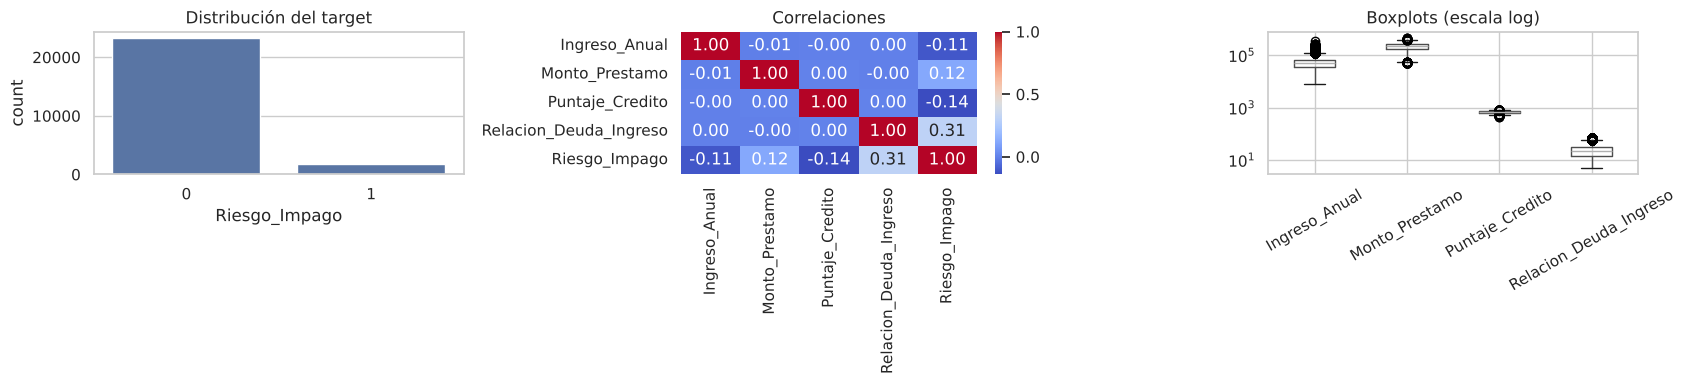

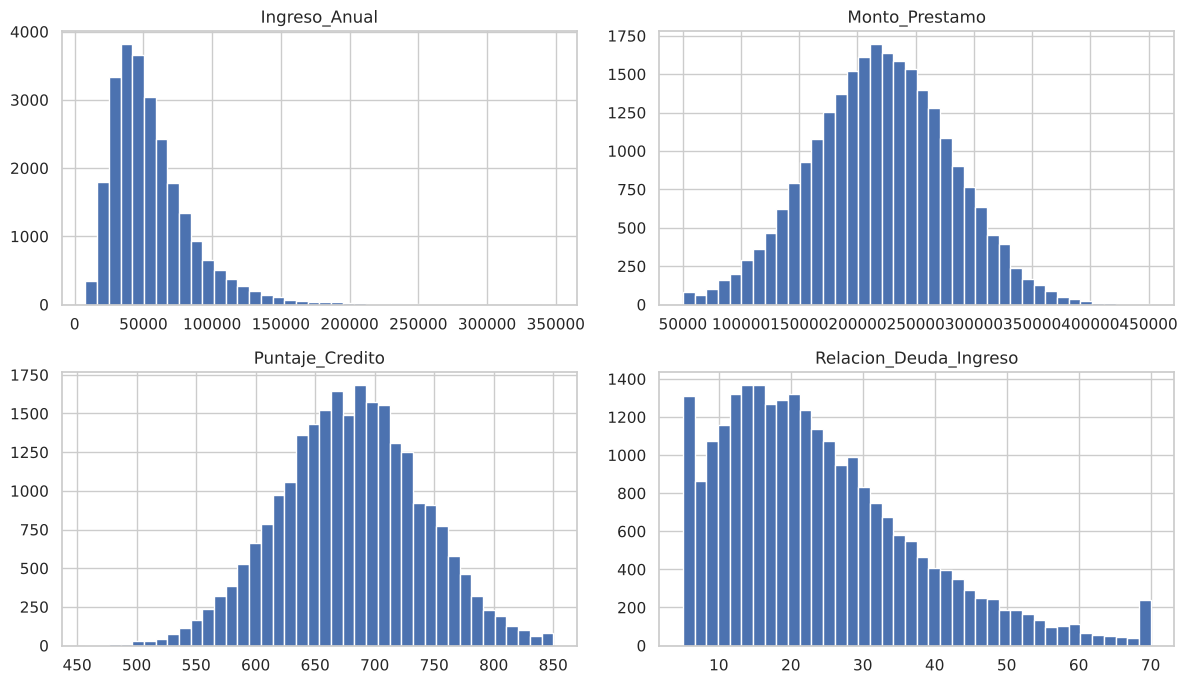

In [4]:
# Desbalance del target
vc = df[TARGET].value_counts(); print(vc, '\n', df[TARGET].value_counts(normalize=True).round(4))
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.countplot(x=TARGET, data=df, ax=ax[0]); ax[0].set_title('Distribución del target')
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax[1]); ax[1].set_title('Correlaciones')
df.drop(columns=TARGET).boxplot(ax=ax[2], rot=30); ax[2].set_yscale('log'); ax[2].set_title('Boxplots (escala log)')
plt.tight_layout(); plt.show()
df.drop(columns=TARGET).hist(bins=40, figsize=(12, 7)); plt.tight_layout(); plt.show()

**Hallazgos:** sin nulos ni duplicados; sin montos/ingresos ≤ 0; puntaje dentro de 300–850. Target fuertemente desbalanceado (~7,2 % de impagos), por lo que *accuracy* es engañosa. Ingreso y monto tienen cola derecha larga (outliers legítimos, no errores: se conservan; los árboles son robustos a ellos). DTI y puntaje presentan topes (70 y 850). La correlación más fuerte con el impago es DTI (+0,31).

## Fase 2 – Pipeline de limpieza y tratamiento

In [5]:
features = df.drop(columns=TARGET).columns.tolist()
preprocesador = ColumnTransformer([
    ('num', Pipeline([('imputar', SimpleImputer(strategy='median')),   # robusto a outliers
                      ('escalar', StandardScaler())]), features)])
# Las transformaciones se ajustan SOLO con train dentro del Pipeline -> sin data leakage.

## Fase 3 – Construcción del modelo

In [6]:
X, y = df[features], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RS)
print(y_train.mean().round(4), y_test.mean().round(4))   # misma tasa de impago en ambos

0.0716 0.0716


In [7]:
# Línea base: árbol por defecto
modelo_base = Pipeline([('pre', preprocesador), ('clf', DecisionTreeClassifier(random_state=RS))])
modelo_base.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['Ingreso_Anual','Monto_Prestamo','Puntaje_Credito', 'Relacion_Deuda_Ingreso']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns th

In [8]:
# Modelo optimizado: GridSearchCV con 5 hiperparámetros, CV estratificada
pipe = Pipeline([('pre', preprocesador), ('clf', DecisionTreeClassifier(random_state=RS))])
param_grid = {
    'clf__max_depth': [3, 5, 7, 10],
    'clf__min_samples_split': [2, 50],
    'clf__min_samples_leaf': [1, 25, 50],
    'clf__criterion': ['gini', 'entropy'],
    'clf__class_weight': [None, 'balanced', {0: 1, 1: 7.5}],  # 7.5 = razón de costos 1.5M/200k
}
# F2 pondera el recall el doble que la precisión, coherente con FN >> FP en costo
f2 = make_scorer(fbeta_score, beta=2)
gs = GridSearchCV(pipe, param_grid, scoring=f2, cv=StratifiedKFold(5, shuffle=True, random_state=RS), n_jobs=-1)
gs.fit(X_train, y_train)
modelo_opt = gs.best_estimator_
print('Mejores hiperparámetros:', gs.best_params_); print('F2 CV:', round(gs.best_score_, 4))

Mejores hiperparámetros: {'clf__class_weight': {0: 1, 1: 7.5}, 'clf__criterion': 'gini', 'clf__max_depth': 7, 'clf__min_samples_leaf': 50, 'clf__min_samples_split': 2}
F2 CV: 0.4707


## Fase 4 – Evaluación sobre el conjunto de prueba
**Métricas elegidas:** *Recall* de la clase impago (mide cuántos morosos reales detectamos; cada FN cuesta $1,5 M) y *Precision* de la clase impago (controla cuántos buenos clientes rechazamos; cada FP cuesta $0,2 M). *Accuracy* se descarta: un modelo que aprueba a todos tendría ~93 % y 0 % de recall.

In [9]:
filas, cms = [], {}
for nombre, m in [('Línea base', modelo_base), ('Optimizado', modelo_opt)]:
    p = m.predict(X_test); tn, fp, fn, tp = confusion_matrix(y_test, p).ravel(); cms[nombre] = confusion_matrix(y_test, p)
    filas.append({'Modelo': nombre, 'Recall (impago)': recall_score(y_test, p), 'Precision (impago)': precision_score(y_test, p),
                  'F1': f1_score(y_test, p), 'VN': tn, 'FP': fp, 'FN': fn, 'VP': tp,
                  'Costo total ($)': fn*COSTO_FN + fp*COSTO_FP,
                  'Recall train': recall_score(y_train, m.predict(X_train))})
res = pd.DataFrame(filas).set_index('Modelo'); display(res.round(3))
print('Referencia: aprobar a todos =', f'${y_test.sum()*COSTO_FN:,.0f}', '| rechazar a todos =', f'${(y_test==0).sum()*COSTO_FP:,.0f}')

,Recall (impago),Precision (impago),F1,VN,FP,FN,VP,Costo total ($),Recall train
Modelo,,,,,,,,,
Línea base,0.313,0.286,0.299,4363,279,246,112,424800000,1.000
Optimizado,0.609,0.265,0.369,4036,606,140,218,331200000,0.655


Referencia: aprobar a todos = $537,000,000 | rechazar a todos = $928,400,000


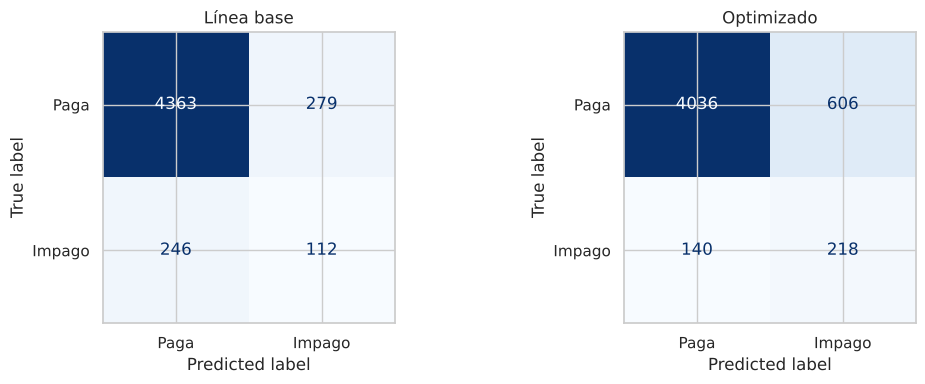

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (n, cm) in zip(ax, cms.items()):
    ConfusionMatrixDisplay(cm, display_labels=['Paga', 'Impago']).plot(ax=a, cmap='Blues', colorbar=False); a.set_title(n)
plt.tight_layout(); plt.show()

## Interpretación de la matriz de confusión (impacto financiero)

**Línea base (árbol sin restricciones).** Memoriza el entrenamiento (recall train = 1,00) y cae a recall ≈ 0,31 en prueba: detecta solo 112 de 358 morosos; 246 créditos malos se otorgan (FN) = $369 M, más 279 buenos clientes rechazados (FP) = $55,8 M. Costo total ≈ **$424,8 M**.

**Optimizado.** Detecta 218 de 358 morosos (recall ≈ 0,61), dejando pasar 140 (FN) = $210 M. A cambio rechaza 606 buenos clientes (FP) = $121,2 M. Costo total ≈ **$331,2 M**, un **22 % menos** que la base y 38 % menos que aprobar a todos ($537 M).

**Lectura de negocio.** Un FN es 7,5 veces más caro que un FP, por lo que conviene aceptar más FP (la precision baja a ≈ 0,26 y sube el rechazo de clientes viables) para capturar más impagos. Sigue habiendo ≈ 3 de cada 5 créditos rechazados que habrían sido pagados; esto es el costo de oportunidad aceptado.
